# Scenario lab - transition levers for EMT Madrid

**IE Sustainability Datathon (Kearney) · supplementary notebook · not a deliverable**

This notebook tests transition strategies that the brief's two mandatory scenarios cannot express.
`File_4.csv` is fixed at **20 rows - 2026-2035 x scenario {0, 1}** and the final compliance cell in
notebook 01 asserts exactly that, so a third strategy can never live in the deliverable. Following the
README rule - *supplementary analyses are printed in the notebook, never written into `File_1-4.csv`* -
everything here stays on screen.

**The question.** EMT runs 1,748 CNG buses at a mean age of 6.6 years. Reaching 100% zero-emission
means retiring most of them long before the end of their life. **Retrofitting** a CNG bus to
battery-electric keeps the vehicle and replaces the driveline. Is that cheaper, faster or
lower-carbon than scrapping and buying new - and if so, which lines should go first?

**What the model does.** One pure function, `simulate(scenario)`, returns a year-by-year table.
S0 and S1 are two entries in a registry; retrofit strategies are more entries. Every lever lives in
the scenario dict, so each one is a sensitivity.

**What it cannot answer yet.** Depot-level charging. Sections 5 (depot allocation) and 6 (connection
capacity) are still stubs in notebook 01, so this notebook reports **city-wide** power only. Per-depot
answers - where Sanchinarro's evidenced 8 MW actually bites - need section 5 first.

> **Every cost, range and life figure below is a placeholder labelled `A`.** They are listed in the
> assumptions register in section 7. Do not quote any of them until they are sourced.

## 0 · Setup

Inputs come from notebook 01 through `data_derived/` - the same pattern notebook 02 uses for
`benchmark_gtfs_intermediate.csv`. The brief's fixed parameters are **read out of notebook 01's own
parameter cell** rather than copied, so there is only ever one copy of the brief's numbers
(README rule 1).

To produce the inputs: open notebook 01, run it through section 4, then run this once:

```python
line_out = line_table[["line_id","daily_km","peak_buses","km_per_bus_day","bus_type",
                       "energy_kwh_bus_day","charging_strategy","co2_avoided_t_year"]].copy()
line_out.insert(0, "route_id", line_table.index)
line_out.to_csv(os.path.join(DERIVED, "line_table.csv"), index=False, encoding="utf-8")
blk.to_csv(os.path.join(DERIVED, "blocks.csv"), index=False, encoding="utf-8")
f25[["vehicleId","fuelType","size","age_years"]].to_csv(
    os.path.join(DERIVED, "fleet_2025.csv"), index=False, encoding="utf-8")
json.dump(dict(BASELINE_2025=BASELINE_2025, REF_DATE=REF_DATE, SUPPLY_DATE=SUPPLY_DATE,
               ZE_2020=int(ZE_2020), S0_PACE_UNADJUSTED=float(S0_PACE_UNADJUSTED)),
          open(os.path.join(DERIVED, "baseline.json"), "w"), indent=1)
```

In [1]:
# Environment: runs as-is in Google Colab (Python 3.10+).
%pip install -q pandas numpy matplotlib

import os, json, math, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = "/content/datathon" if os.path.exists("/content") else os.path.abspath("..")
RAW, DERIVED, OUT = (os.path.join(BASE, d) for d in ("data_raw", "data_derived", "outputs"))
RUN_DATE = dt.date.today().isoformat()

# Categorical palette: fixed slot order, never cycled (light chart surface).
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#dcdcd8"
plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
print(f"Run date {RUN_DATE} | pandas {pd.__version__} | base {BASE}")

**Helpers.** Same contract as notebook 01: `assume()` labels every value **V** verified · **D** derived ·
**P** proxy · **A** assumption, and `check()` prints a visible PASS/FAIL line.

In [2]:
ASSUMPTIONS, CHECKS = [], []

def assume(variable, value, label, evidence, impact="", sensitivity=""):
    assert label in {"V", "D", "P", "A"}, "label must be V, D, P or A"
    ASSUMPTIONS.append(dict(variable=variable, value=value, label=label, evidence=evidence,
                            impact=impact, sensitivity=sensitivity))
    return value

def check(name, ok, detail=""):
    ok = bool(ok)
    CHECKS.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))
    print(f"CHECK {'PASS' if ok else 'FAIL'} | {name}" + (f" | {detail}" if detail else ""))
    return ok

In [3]:
# The brief's fixed parameters are read out of notebook 01's own parameter cell, never copied here:
# one source of truth for every number in brief section 4.5 (README rule 1).
def load_P_from_main_notebook():
    path = os.path.join(BASE, "notebooks", "01_Madrid_Electrification_Main.ipynb")
    for c in json.load(open(path))["cells"]:
        src = "".join(c["source"])
        if c["cell_type"] == "code" and "P = dict(" in src:
            g = {"assume": assume, "pd": pd, "np": np, "display": lambda *a, **k: None}
            exec(src, g)
            return g["P"]
    raise RuntimeError("parameter cell 'P = dict(...)' not found in notebook 01 - has section 0 moved?")

P = load_P_from_main_notebook()
check("Brief parameters loaded from notebook 01 section 0",
      {"kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "service_days", "charge_eff"} <= set(P),
      f"{len(P)} parameters")
print({k: P[k] for k in ("kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "charge_eff", "service_days")})

CHECK PASS | Brief parameters loaded from notebook 01 section 0 | 11 parameters
{'kwh_km': {'Standard': 1.3, 'Articulated': 1.85}, 'range_km': {'Standard': 300, 'Articulated': 240}, 'cng_kg_km': {'Standard': 0.45, 'Articulated': 0.65}, 'bus_price_eur': {'Standard': 615000, 'Articulated': 800000}, 'charge_eff': 0.9, 'service_days': 365}


In [4]:
# Inputs from notebook 01 (git-ignored intermediates; the markdown above says how to regenerate them).
NEEDED = {
    "line_table.csv": "section 4 line model",
    "blocks.csv":     "section 4 per-block km",
    "fleet_2025.csv": "section 3 fleet at 31 Dec 2025",
    "baseline.json":  "section 3 BASELINE_2025",
}
missing = [f for f in NEEDED if not os.path.exists(os.path.join(DERIVED, f))]
if missing:
    raise FileNotFoundError(
        "Missing notebook 01 intermediates in data_derived/: " + ", ".join(missing) +
        "\nRun notebook 01 through section 4, then the export snippet in the markdown cell above.")

lines_in = pd.read_csv(os.path.join(DERIVED, "line_table.csv"), dtype={"route_id": str, "line_id": str})
blocks   = pd.read_csv(os.path.join(DERIVED, "blocks.csv"), dtype={"route_id": str, "block_id": str})
fleet25  = pd.read_csv(os.path.join(DERIVED, "fleet_2025.csv"), dtype={"vehicleId": str})
meta     = json.load(open(os.path.join(DERIVED, "baseline.json")))
B25, REF_DATE = meta["BASELINE_2025"], meta["REF_DATE"]

PEAK_TOTAL = int(lines_in.peak_buses.sum())
SPARE_2025 = B25["fleet_total"] - PEAK_TOTAL

print(f"Reference day {REF_DATE} | lines {len(lines_in)} | daily km {lines_in.daily_km.sum():,.0f}"
      f" | peak buses {PEAK_TOTAL:,}")
print(f"Fleet {B25['fleet_total']:,} = {B25['n_bev']} BEV + {B25['n_h2']} H2 + {B25['n_cng']} CNG"
      f" | spare over peak: {SPARE_2025}")
print(f"Blocks {len(blocks):,} | over range at today's ranges: {int(blocks.over_range.sum())}")
print(f"Bus type mix: {lines_in.bus_type.value_counts().to_dict()}")
display(lines_in.head(5))
check("Fleet identity at 31 Dec 2025", B25["n_bev"] + B25["n_h2"] + B25["n_cng"] == B25["fleet_total"])
check("Every line has a positive peak_buses and daily_km",
      (lines_in.peak_buses > 0).all() and (lines_in.daily_km > 0).all())
_ = check("Spare buses over peak demand is positive", SPARE_2025 > 0, f"{SPARE_2025} buses")

Reference day 2026-11-18 | lines 234 | daily km 341,422 | peak buses 1,994
Fleet 2,210 = 452 BEV + 10 H2 + 1748 CNG | spare over peak: 216
Blocks 2,106 | over range at today's ranges: 74
Bus type mix: {'Standard': 226, 'Articulated': 8}


,route_id,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,energy_kwh_bus_day,charging_strategy,co2_avoided_t_year
0,001,1,1392.458105,11,126.587100,Standard,164.563231,Depot,541.942587
1,002,2,1990.403987,14,142.171713,Standard,184.823227,Depot,774.662219
2,003,3,1777.251381,13,136.711645,Standard,177.725138,Depot,691.703547
3,004,4,1592.927612,10,159.292761,Standard,207.080590,Depot,619.965015
4,005,5,1575.084799,10,157.508480,Standard,204.761024,Depot,613.020619


CHECK PASS | Fleet identity at 31 Dec 2025
CHECK PASS | Every line has a positive peak_buses and daily_km
CHECK PASS | Spare buses over peak demand is positive | 216 buses


## 1 · Levers

Every lever is a named value that `simulate()` can override, so any of them can be swept. **The five
marked `TODO(research)` are placeholders.** The first is load-bearing: if CNG-to-electric repowering
is not a product EMT can buy, the whole retrofit family collapses into "what would have to be true".

In [5]:
# ---- Retrofit technology and cost ---------------------------------------------------------------
# TODO(research) Confirm CNG-to-battery repowering is commercially offered for EMT's chassis -- most
#   European retrofit programmes convert diesel, not CNG -- and obtain a real price per bus.
RETRO_COST = assume("Retrofit cost per bus (EUR)", {"Standard": 250_000, "Articulated": 320_000}, "A",
                    "PLACEHOLDER, not sourced: set at about 40% of a new bus. Drives the whole business case",
                    "capex_meur", "swept: 150k / 250k / 400k")

RETRO_RANGE_MULT = assume("Retrofit range as a share of a new BEV's", 0.70, "A",
                          "PLACEHOLDER: a repowered bus carries a smaller pack than a purpose-built BEV, "
                          "because the gas-tank space and axle loads constrain it",
                          "charging_strategy, blocks over range", "swept: 0.55 / 0.70 / 0.85")

RETRO_KWH_MULT = assume("Retrofit energy use as a share of a new BEV's", 1.05, "A",
                        "PLACEHOLDER: a converted bus is heavier and less aerodynamically optimised",
                        "electricity_mwh, co2_t")

RETRO_MAX_AGE = assume("Oldest CNG bus worth retrofitting (age at conversion, years)", 10, "A",
                       "PLACEHOLDER: beyond this the body and chassis need work a repower does not cover",
                       "size of the eligible pool")

RETRO_DOWNTIME_M = assume("Months a bus is out of service per retrofit", 3, "A",
                          "PLACEHOLDER: conversion, type approval and commissioning",
                          "buses in the shop against the spare fleet")

# ---- Fleet and operations -----------------------------------------------------------------------
BUS_LIFE = assume("CNG bus service life (years)", 14, "A",
                  "PLACEHOLDER: typical European urban bus life. Sets how many CNG buses retire "
                  "naturally before 2035, and therefore how many are scrapped early",
                  "early-scrapping count, capex", "swept: 12 / 14 / 16")

CHARGER_CAPEX = assume("Charging infrastructure per bus (EUR)", 40_000, "A",
                       "PLACEHOLDER: depot charger, civils and a share of the connection upgrade",
                       "capex_meur")

# TODO(research) Grid decarbonisation path to 2035 (PNIEC / Red Electrica projections).
GRID_2035 = assume("Spain grid CO2 intensity in 2035 (gCO2/kWh)", 40.0, "A",
                   "PLACEHOLDER: interpolated linearly from the 2025 value in P. Holding 2025 flat to "
                   "2035 would understate the benefit of electrifying early",
                   "co2_t in later years", "flat 108.4 against 40")

print(f"Range km     new {P['range_km']}")
print(f"             retrofit { {k: round(v * RETRO_RANGE_MULT) for k, v in P['range_km'].items()} }")
print(f"Price EUR    new {P['bus_price_eur']}")
print(f"             retrofit {RETRO_COST}")
print(f"Grid gCO2/kWh  2025 {P['grid_gco2_kwh']} -> 2035 {GRID_2035}")

Range km     new {'Standard': 300, 'Articulated': 240}
             retrofit {'Standard': 210, 'Articulated': 168}
Price EUR    new {'Standard': 615000, 'Articulated': 800000}
             retrofit {'Standard': 250000, 'Articulated': 320000}
Grid gCO2/kWh  2025 108.4 -> 2035 40.0


**The eligible pool.** Retrofit only makes sense on buses with life left in them. The age profile
decides how big that pool is - and how many buses a 2030 target would scrap early.

In [6]:
# ---- The eligible retrofit pool, from the real age distribution ---------------------------------
cng25 = fleet25[fleet25.fuelType == "GN"].copy()

def retire_year(age, life):
    # A bus retires in the year it reaches `life` years of age.
    return 2025 + max(int(math.ceil(life - age)), 0)

cng25["retire_default"] = cng25.age_years.apply(lambda a: retire_year(a, BUS_LIFE))
elig = cng25[cng25.age_years <= RETRO_MAX_AGE]
natural = cng25[cng25.retire_default <= 2035]

print(f"CNG at 31 Dec 2025: {len(cng25):,} | mean age {cng25.age_years.mean():.1f} y | "
      f"oldest {cng25.age_years.max():.1f} y")
print(f"Eligible for retrofit today (age <= {RETRO_MAX_AGE}): {len(elig):,} "
      f"({len(elig)/len(cng25):.0%}) | by size {elig['size'].value_counts().to_dict()}")
print(f"Retire naturally by 2035 at a {BUS_LIFE}-year life: {len(natural):,} "
      f"| still running in 2035: {len(cng25) - len(natural):,}")
print(f"=> reaching zero CNG by 2035 means scrapping about "
      f"{len(cng25) - len(natural):,} buses before the end of their life, or retrofitting them")
display(cng25.retire_default.value_counts().sort_index().rename("CNG buses retiring").to_frame().T)
_ = check("Every CNG bus has a size and an age",
      cng25["size"].notna().all() and cng25.age_years.notna().all())

CNG at 31 Dec 2025: 1,748 | mean age 6.6 y | oldest 15.1 y
Eligible for retrofit today (age <= 10): 1,623 (93%) | by size {'Standard': 1569, 'Articulated': 54}
Retire naturally by 2035 at a 14-year life: 1,332 | still running in 2035: 416
=> reaching zero CNG by 2035 means scrapping about 416 buses before the end of their life, or retrofitting them


retire_default,2025,2026,2027,2030,2031,2032,2033,2034,2035,2036,2037
CNG buses retiring,67,39,19,43,231,365,231,233,104,304,112


CHECK PASS | Every CNG bus has a size and an age


## 2 · The model

`simulate(scenario)` walks 2026 to 2035 one year at a time. In each year:

1. **Retire** the CNG buses that reach `bus_life`; each one forces a replacement purchase.
2. **Retrofit** up to the scenario's throughput from the eligible pool, youngest first.
3. **Scrap early** as many of the oldest remaining CNG buses as the scenario's extra procurement
   replaces, which is what holds the fleet at its 2025 size.
4. **Allocate** the zero-emission fleet to lines in the scenario's priority order, matching bus size.
   Retrofits go to lines whose duty fits their shorter range; new BEVs take the rest.
5. **Account** energy, fuel, CO2 and capex from the lines actually converted - never from a fleet share.

Step 4 is what makes "which lines first" a result rather than an input: a line converts only when
enough buses of the right size exist to cover its whole peak requirement.

In [7]:
YEARS = list(range(2026, 2036))

# Default levers. simulate() takes a scenario dict that overrides any of these, so every lever
# is a sensitivity and nothing is hard-coded per scenario.
DEFAULTS = dict(
    retrofit_per_year=0, new_bev_per_year=0, allocation_policy="shortest_duty_first",
    retro_cost=RETRO_COST, retro_range_mult=RETRO_RANGE_MULT, retro_kwh_mult=RETRO_KWH_MULT,
    retro_max_age=RETRO_MAX_AGE, downtime_months=RETRO_DOWNTIME_M,
    bus_life=BUS_LIFE, charger_capex=CHARGER_CAPEX, grid_2035=GRID_2035,
)

# Counterfactual: the whole network run on CNG for a year. co2_avoided is measured against this.
CO2_ALL_CNG_T = float((lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"])
                       * P["service_days"] * P["cng_kgco2_per_kg"] / 1000).sum())
print(f"Counterfactual, whole network on CNG: {CO2_ALL_CNG_T:,.0f} tCO2 a year")

def per_year(v, year):
    # A lever may be a flat number or a {year: number} schedule.
    return int(v.get(year, 0)) if isinstance(v, dict) else int(v)

def grid_g(year, L):
    f = min(max((year - 2025) / 10.0, 0.0), 1.0)
    return P["grid_gco2_kwh"] + (L["grid_2035"] - P["grid_gco2_kwh"]) * f

# What the network actually needs, by bus size. New purchases close the articulated gap first:
# the 2025 register mix (3.9% articulated) is a fleet share, not a demand share, and applying it to
# purchases leaves the articulated lines a few buses short for years.
DEMAND_BY_SIZE = lines_in.groupby("bus_type").peak_buses.sum().to_dict()

def split_by_size(n, std_share):
    # Split a count of buses into Standard / Articulated on the register's observed share.
    art = int(round(n * (1 - std_share)))
    return {"Standard": n - art, "Articulated": art}

def allocate(pool, policy, retro_range):
    # Assign the zero-emission fleet to whole lines in priority order, matching bus size.
    # pool: {("retro"|"new", size): count}. A line converts only when the pool covers all of its
    # peak_buses, so partial conversions never appear.
    #
    # Two passes, because a retrofit's shorter range makes the pools non-interchangeable: lines whose
    # duty a retrofit cannot cover get first claim on new buses, then the lines that fit take
    # retrofits first. Serving everything in one pass lets short lines spend new buses that only the
    # long lines can use, which strands retrofits in the yard.
    if policy == "shortest_duty_first":
        order = lines_in.sort_values("km_per_bus_day")
    elif policy == "co2_first":
        order = lines_in.sort_values("co2_avoided_t_year", ascending=False)
    elif policy == "fewest_buses_first":
        order = lines_in.sort_values("peak_buses")
    else:
        raise ValueError(f"unknown allocation policy {policy!r}")

    fits = order.km_per_bus_day <= order.bus_type.map(retro_range)
    pool, rows = dict(pool), []
    for phase in (order[~fits], order[fits]):
        for L in phase.itertuples():
            size, need = L.bus_type, int(L.peak_buses)
            take_r = min(need, pool.get(("retro", size), 0)) if L.km_per_bus_day <= retro_range[size] else 0
            take_n = min(need - take_r, pool.get(("new", size), 0))
            if take_r + take_n < need:
                continue                 # cannot cover this line yet; try the next one
            pool[("retro", size)] = pool.get(("retro", size), 0) - take_r
            pool[("new", size)] = pool.get(("new", size), 0) - take_n
            rows.append(dict(route_id=L.route_id, line_id=L.line_id, bus_type=size, peak_buses=need,
                             daily_km=L.daily_km, km_per_bus_day=L.km_per_bus_day,
                             n_retro=take_r, n_new=take_n))
    cols = ["route_id", "line_id", "bus_type", "peak_buses", "daily_km", "km_per_bus_day",
            "n_retro", "n_new"]
    return (pd.DataFrame(rows) if rows else pd.DataFrame(columns=cols)), pool

def account(conv, year, L, retro_range):
    # Energy, fuel, CO2 and scheduling diagnostics for one year, from the lines actually converted.
    done = set(conv.route_id)
    not_conv = lines_in[~lines_in.route_id.isin(done)]

    if len(conv):
        base_kwh = conv.bus_type.map(P["kwh_km"])
        # A line may be served by both pools, so weight kWh/km by how many buses of each.
        w_kwh = (conv.n_retro * base_kwh * L["retro_kwh_mult"] + conv.n_new * base_kwh) / conv.peak_buses
        kwh_day = float((conv.daily_km * w_kwh).sum())           # energy at the wheel
    else:
        kwh_day = 0.0
    elec_co2_t = kwh_day / P["charge_eff"] * grid_g(year, L) / 1000 * P["service_days"] / 1000

    cng_t = float((not_conv.daily_km * not_conv.bus_type.map(P["cng_kg_km"])).sum()) * P["service_days"] / 1000
    cng_co2_t = cng_t * P["cng_kgco2_per_kg"]

    # Scheduling: a line carrying any retrofit is limited by the retrofit range.
    if len(conv):
        eff = np.where(conv.n_retro > 0, conv.bus_type.map(retro_range), conv.bus_type.map(P["range_km"]))
        strat = np.select([conv.km_per_bus_day <= eff, conv.km_per_bus_day <= 2.0 * eff],
                          ["Depot", "Opportunity"], "Not_feasible")
        rng = dict(zip(conv.route_id, eff))
        b = blocks[blocks.route_id.isin(rng)]
        over = int((b.block_km > b.route_id.map(rng)).sum())
    else:
        strat, over = np.array([]), 0

    return dict(
        lines_converted=len(conv),
        buses_on_ze_lines=int(conv.peak_buses.sum()) if len(conv) else 0,
        km_share_converted=round(float(conv.daily_km.sum() / lines_in.daily_km.sum()), 4) if len(conv) else 0.0,
        electricity_mwh=round(kwh_day * P["service_days"] / 1000, 1),
        cng_t=round(cng_t, 1),
        co2_t=round(elec_co2_t + cng_co2_t, 1),
        co2_avoided_t=round(CO2_ALL_CNG_T - (elec_co2_t + cng_co2_t), 1),
        night_mwh_day=round(kwh_day / 1000, 1),
        peak_mw_managed=round(kwh_day / 1000 / (P["window_h"] * P["charge_eff"]), 1),
        lines_depot=int((strat == "Depot").sum()),
        lines_opportunity=int((strat == "Opportunity").sum()),
        lines_not_feasible=int((strat == "Not_feasible").sum()),
        blocks_over_range=over,
    )

def simulate(sc):
    # One scenario -> a year-by-year table. Pure: reads globals, mutates none.
    L = {**DEFAULTS, **sc}
    retro_range = {k: v * L["retro_range_mult"] for k, v in P["range_km"].items()}

    cng = cng25[["vehicleId", "size", "age_years"]].copy()
    cng["retire_year"] = cng.age_years.apply(lambda a: retire_year(a, L["bus_life"]))
    cng["state"] = "cng"

    ze0 = split_by_size(B25["n_bev"] + B25["n_h2"], B25["std_share"])
    bought = {"Standard": 0, "Articulated": 0}
    spare = B25["fleet_total"] - PEAK_TOTAL
    out = []

    for y in YEARS:
        cap_r, cap_n = per_year(L["retrofit_per_year"], y), per_year(L["new_bev_per_year"], y)

        # 1. natural retirement: each retiring bus forces a replacement purchase
        idx = cng.index[(cng.state == "cng") & (cng.retire_year <= y)]
        cng.loc[idx, "state"] = "retired"
        n_retired = len(idx)

        # 2. retrofit the youngest eligible buses, within the scenario's throughput
        age_now = cng.age_years + (y - 2025)
        avail = cng[(cng.state == "cng") & (age_now <= L["retro_max_age"])]
        take = avail.nsmallest(min(cap_r, len(avail)), "age_years")
        cng.loc[take.index, "state"] = "retrofit"

        # 3. extra procurement scraps the oldest remaining CNG buses early
        rest = cng[cng.state == "cng"]
        early = rest.nlargest(min(cap_n, len(rest)), "age_years")
        cng.loc[early.index, "state"] = "scrapped_early"

        # 4. buy new buses to replace everything that left the fleet this year, closing the
        #    articulated gap first so the articulated lines are not starved by a fleet-share split
        n_retro = int((cng.state == "retrofit").sum())
        n_cng = int((cng.state == "cng").sum())
        retro_sizes = cng.loc[cng.state == "retrofit", "size"].value_counts().to_dict()

        n_buy = n_retired + len(early)
        art_supply = ze0["Articulated"] + bought["Articulated"] + int(retro_sizes.get("Articulated", 0))
        buy_art = min(n_buy, max(DEMAND_BY_SIZE.get("Articulated", 0) - art_supply, 0))
        bought["Articulated"] += buy_art
        bought["Standard"] += n_buy - buy_art
        bought_split = {"Standard": n_buy - buy_art, "Articulated": buy_art}

        pool = {("new", s): ze0[s] + bought[s] for s in ("Standard", "Articulated")}
        pool.update({("retro", s): int(retro_sizes.get(s, 0)) for s in ("Standard", "Articulated")})

        # 5. allocate to lines, then account
        conv, left = allocate(pool, L["allocation_policy"], retro_range)

        n_bev = B25["n_bev"] + sum(bought.values()) + n_retro
        fleet_total = n_bev + B25["n_h2"] + n_cng
        shop = int(round(cap_r * L["downtime_months"] / 12))

        capex = sum(int(n) * L["retro_cost"][s] for s, n in take["size"].value_counts().items())
        for s, n in bought_split.items():
            capex += n * P["bus_price_eur"][s]
        capex += (len(take) + n_buy) * L["charger_capex"]

        row = dict(scenario=L["name"], year=y, fleet_total=fleet_total, n_bev=n_bev,
                   n_h2=B25["n_h2"], n_cng=n_cng, n_bev_retrofit=n_retro,
                   n_bev_new=n_bev - n_retro,
                   ze_share_pct=round(100 * (n_bev + B25["n_h2"]) / fleet_total, 1),
                   retrofits_this_year=len(take), bought_this_year=n_buy,
                   retired_this_year=n_retired, scrapped_early_this_year=len(early),
                   early_scrapped_cum=int((cng.state == "scrapped_early").sum()),
                   buses_in_shop=shop, spare_buses=spare, shop_within_spare=shop <= spare,
                   max_retrofits_per_year=int(spare * 12 / L["downtime_months"]),
                   idle_retro=int(sum(v for (k, _), v in left.items() if k == "retro")),
                   idle_new=int(sum(v for (k, _), v in left.items() if k == "new")),
                   lines_unconverted=len(lines_in) - len(conv),
                   capex_meur=round(capex / 1e6, 2))
        row.update(account(conv, y, L, retro_range))
        out.append(row)

    df = pd.DataFrame(out)
    df["capex_cum_meur"] = df.capex_meur.cumsum().round(1)
    return df

Counterfactual, whole network on CNG: 154,882 tCO2 a year


## 3 · Scenarios

S0 and S1 are the brief's two. S0 extends the 2021-25 pace. **S1 is the mandated target, and notebook
01's compliance cell requires 100% zero-emission from 2030** - not 2035 - which is what makes it so
demanding: every CNG bus has to go in five years.

The `R` scenarios are the retrofit family. Each changes only its levers.

In [8]:
S0_PACE = int(round(meta["S0_PACE_UNADJUSTED"]))
S1_RATE = math.ceil(B25["n_cng"] / 5)        # 2026-2030 inclusive: every CNG bus gone by 2030

SCENARIOS = [
    dict(name="S0 pace",          new_bev_per_year=S0_PACE, retrofit_per_year=0),
    dict(name="S1 all ZE by 2030", new_bev_per_year=S1_RATE, retrofit_per_year=0),
    dict(name="R1 retrofit-led",  new_bev_per_year=100, retrofit_per_year=250),
    dict(name="R2 retrofit max",  new_bev_per_year=0,   retrofit_per_year=350),
    dict(name="R3 balanced",      new_bev_per_year=180, retrofit_per_year=180),
    dict(name="R4 R1, CO2 order", new_bev_per_year=100, retrofit_per_year=250,
         allocation_policy="co2_first"),
]
print(f"S0 pace {S0_PACE} buses/yr (section 3) | S1 needs {S1_RATE}/yr to clear "
      f"{B25['n_cng']:,} CNG buses by 2030 -- {S1_RATE/S0_PACE:.1f}x the historical pace")

runs = pd.concat([simulate(s) for s in SCENARIOS], ignore_index=True)

check("Fleet identity holds in every scenario-year",
      (runs.n_bev + runs.n_h2 + runs.n_cng == runs.fleet_total).all())
check("Fleet total stays at the 2025 size",
      (runs.fleet_total == B25["fleet_total"]).all(),
      f"{sorted(runs.fleet_total.unique())}")
check("ze_share_pct matches the fleet mix",
      np.allclose(runs.ze_share_pct, (100 * (runs.n_bev + runs.n_h2) / runs.fleet_total).round(1),
                  atol=0.051))
check("CNG count never increases", (runs.groupby("scenario").n_cng.diff().fillna(0) <= 0).all())
check("Retrofits never exceed the CNG fleet that existed in 2025",
      runs.n_bev_retrofit.max() <= len(cng25))
check("Converted lines never exceed the network", runs.lines_converted.max() <= len(lines_in))
display(runs[runs.scenario == "R1 retrofit-led"][
    ["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "lines_converted",
     "km_share_converted", "capex_meur"]])

S0 pace 77 buses/yr (section 3) | S1 needs 350/yr to clear 1,748 CNG buses by 2030 -- 4.5x the historical pace


CHECK PASS | Fleet identity holds in every scenario-year
CHECK PASS | Fleet total stays at the 2025 size | [np.int64(2210)]
CHECK PASS | ze_share_pct matches the fleet mix
CHECK PASS | CNG count never increases
CHECK PASS | Retrofits never exceed the CNG fleet that existed in 2025
CHECK PASS | Converted lines never exceed the network


,year,n_cng,n_bev_retrofit,n_bev_new,ze_share_pct,lines_converted,km_share_converted,capex_meur
20,2026,1292,250,658,41.5,130,0.4598,218.34
21,2027,942,500,758,57.4,159,0.6161,138.00
22,2028,592,750,858,73.2,194,0.7869,138.00
23,2029,489,753,958,77.9,205,0.8412,66.37
24,2030,389,753,1058,82.4,218,0.8973,65.50
25,2031,289,753,1158,86.9,227,0.9541,65.50
26,2032,131,753,1316,94.1,234,1.0000,103.49
27,2033,0,753,1447,100.0,234,1.0000,85.81
28,2034,0,753,1447,100.0,234,1.0000,0.00
29,2035,0,753,1447,100.0,234,1.0000,0.00


## 4 · The comparison

One row per scenario: when it gets there, what it costs, what it avoids, and **what stops it**.

In [9]:
def verdict(g):
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    reasons = []
    if not g.shop_within_spare.all():
        reasons.append(f"retrofit shop needs {g.buses_in_shop.max()} buses, only "
                       f"{g.spare_buses.iloc[0]} spare")
    if g.idle_retro.max() > 0:
        reasons.append(f"{g.idle_retro.max()} retrofits stranded (no line short enough)")
    if g.lines_unconverted.min() > 0:
        reasons.append(f"{g.lines_unconverted.min()} lines never converted")
    if g.lines_not_feasible.max() > 0:
        reasons.append(f"{g.lines_not_feasible.max()} lines not feasible on range")
    if g.blocks_over_range.max() > 0:
        reasons.append(f"{g.blocks_over_range.max()} blocks over range")
    if len(hit) == 0:
        reasons.append("100% not reached by 2035")
    return dict(
        ze_100_year=("not by 2035" if len(hit) == 0 else int(hit.min())),
        ze_pct_2030=g.loc[g.year == 2030, "ze_share_pct"].iloc[0],
        ze_pct_2035=g.loc[g.year == 2035, "ze_share_pct"].iloc[0],
        capex_meur=round(g.capex_meur.sum()),
        retrofits=int(g.n_bev_retrofit.max()),
        early_scrapped=int(g.early_scrapped_cum.max()),
        co2_avoided_kt=round(g.co2_avoided_t.sum() / 1000),
        peak_mw_2035=g.loc[g.year == 2035, "peak_mw_managed"].iloc[0],
        shop_peak=int(g.buses_in_shop.max()),
        shop_ceiling=int(g.max_retrofits_per_year.iloc[0]),
        not_feasible=int(g.lines_not_feasible.max()),
        blocks_over=int(g.blocks_over_range.max()),
        binding_constraint="; ".join(reasons) if reasons else "none in this model",
    )

summary = pd.DataFrame([dict(scenario=n, **verdict(g))
                        for n, g in runs.groupby("scenario", sort=False)]).set_index("scenario")
display(summary.drop(columns="binding_constraint"))
print("\nBinding constraint:")
for n, r in summary.iterrows():
    print(f"  {n:22s} {r.binding_constraint}")

print("\nCapex per tonne of CO2 avoided, 2026-2035 (capital only -- no opex, no residual value):")
display((summary.capex_meur * 1e6 / (summary.co2_avoided_kt * 1000)).round(0)
        .rename("EUR per tCO2").to_frame())

,ze_100_year,ze_pct_2030,ze_pct_2035,capex_meur,retrofits,early_scrapped,co2_avoided_kt,peak_mw_2035,shop_peak,shop_ceiling,not_feasible,blocks_over
scenario,,,,,,,,,,,,
S0 pace,not by 2035,43.1,84.7,934,0,770,830,66.4,0,864,0,72
S1 all ZE by 2030,2030,100.0,100.0,1156,0,1642,1264,71.5,0,864,0,74
R1 retrofit-led,2033,82.4,100.0,881,753,700,1222,72.5,62,864,0,82
R2 retrofit max,2032,73.0,100.0,797,984,0,1186,72.9,88,864,0,100
R3 balanced,2031,99.0,100.0,893,720,922,1269,72.5,45,864,0,82
"R4 R1, CO2 order",2033,82.4,100.0,881,753,700,1272,72.8,62,864,0,166



Binding constraint:
  S0 pace                11 lines never converted; 72 blocks over range; 100% not reached by 2035
  S1 all ZE by 2030      74 blocks over range
  R1 retrofit-led        82 blocks over range
  R2 retrofit max        100 blocks over range
  R3 balanced            82 blocks over range
  R4 R1, CO2 order       166 blocks over range

Capex per tonne of CO2 avoided, 2026-2035 (capital only -- no opex, no residual value):


,EUR per tCO2
scenario,
S0 pace,1125.0
S1 all ZE by 2030,915.0
R1 retrofit-led,721.0
R2 retrofit max,672.0
R3 balanced,704.0
"R4 R1, CO2 order",693.0


## 5 · Charts

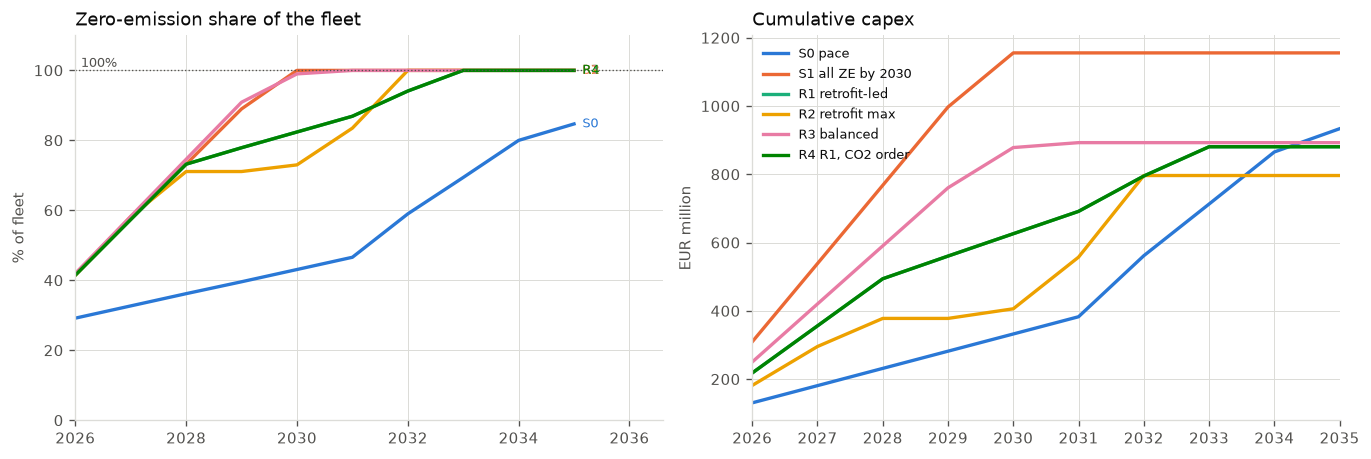

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
for i, (name, g) in enumerate(runs.groupby("scenario", sort=False)):
    ax.plot(g.year, g.ze_share_pct, color=C[i], linewidth=2)
    ax.annotate(name.split(" ")[0], (g.year.iloc[-1], g.ze_share_pct.iloc[-1]),
                xytext=(5, 0), textcoords="offset points", color=C[i], fontsize=8, va="center")
ax.axhline(100, color=INK2, linewidth=0.8, linestyle=":")
ax.annotate("100%", (2026.1, 101), color=INK2, fontsize=7.5)
ax.set_title("Zero-emission share of the fleet", color=INK, loc="left")
ax.set_ylabel("% of fleet"); ax.set_xlim(2026, 2036.6); ax.set_ylim(0, 110)

ax = axes[1]
for i, (name, g) in enumerate(runs.groupby("scenario", sort=False)):
    ax.plot(g.year, g.capex_cum_meur, color=C[i], linewidth=2, label=name)
ax.set_title("Cumulative capex", color=INK, loc="left")
ax.set_ylabel("EUR million"); ax.set_xlim(2026, 2035)
ax.legend(loc="upper left", fontsize=7.5, ncol=1)

fig.tight_layout(); plt.show()

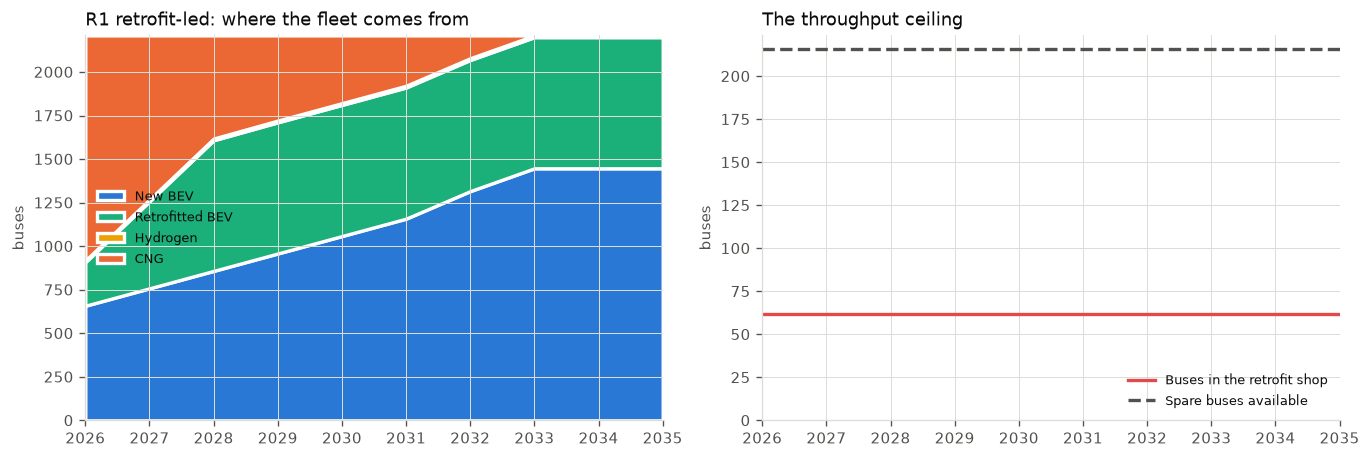

 year  n_cng  n_bev_retrofit  n_bev_new  ze_share_pct  lines_converted  lines_depot  lines_opportunity  lines_not_feasible  blocks_over_range  peak_mw_managed  idle_retro  lines_unconverted  capex_meur
 2026   1292             250        658          41.5              130          119                 11                   0                 70             33.7           0                104      218.34
 2027    942             500        758          57.4              159          148                 11                   0                 72             45.1           0                 75      138.00
 2028    592             750        858          73.2              194          183                 11                   0                 79             57.5           0                 40      138.00
 2029    489             753        958          77.9              205          194                 11                   0                 79             61.4           0                 29   

In [11]:
g = runs[runs.scenario == "R1 retrofit-led"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
ax.stackplot(g.year, g.n_bev_new, g.n_bev_retrofit, g.n_h2, g.n_cng,
             colors=[C[0], C[2], C[3], C[1]], edgecolor="white", linewidth=2,
             labels=["New BEV", "Retrofitted BEV", "Hydrogen", "CNG"])
ax.set_title("R1 retrofit-led: where the fleet comes from", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, B25["fleet_total"])
ax.legend(loc="center left", fontsize=8)

ax = axes[1]
ax.plot(g.year, g.buses_in_shop, color=C[7], linewidth=2, label="Buses in the retrofit shop")
ax.plot(g.year, g.spare_buses, color=INK2, linewidth=2, linestyle="--", label="Spare buses available")
ax.set_title("The throughput ceiling", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, None)
ax.legend(loc="lower right", fontsize=8)

fig.tight_layout(); plt.show()

print(g[["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "lines_converted",
         "lines_depot", "lines_opportunity", "lines_not_feasible", "blocks_over_range",
         "peak_mw_managed", "idle_retro", "lines_unconverted", "capex_meur"]].to_string(index=False))

**Which lines go first.** The two orderings answer different questions: shortest duty first is the
cheapest path to a converted line, biggest CO2 saving first buys the most abatement per line. They
disagree, and the disagreement is the interesting part.

In [12]:
# Which lines go first, and what the two orderings disagree about.
retro_range = {k: v * RETRO_RANGE_MULT for k, v in P["range_km"].items()}
first = lines_in.assign(
    fits_retrofit=lines_in.km_per_bus_day <= lines_in.bus_type.map(retro_range),
    cng_kg_day=lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"]),
)
short = first.sort_values("km_per_bus_day").head(15)
big = first.sort_values("co2_avoided_t_year", ascending=False).head(15)

print(f"Lines whose duty fits a retrofit's {retro_range['Standard']:.0f} km range: "
      f"{int(first.fits_retrofit.sum())} of {len(first)} "
      f"({first.loc[first.fits_retrofit, 'peak_buses'].sum()} buses, "
      f"{first.loc[first.fits_retrofit, 'daily_km'].sum() / first.daily_km.sum():.0%} of daily km)")
print("\nFirst 15 under 'shortest duty first' -- the natural retrofit candidates:")
display(short[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
               "co2_avoided_t_year", "fits_retrofit"]].round(1))
print("First 15 under 'biggest CO2 saving first':")
display(big[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
             "co2_avoided_t_year", "fits_retrofit"]].round(1))
overlap = set(short.line_id) & set(big.line_id)
print(f"Lines in both lists: {len(overlap)} -> {sorted(overlap)}")
_ = check("The two orderings are not the same list",
      len(overlap) < 15, f"{len(overlap)} of 15 overlap")

Lines whose duty fits a retrofit's 210 km range: 182 of 234 (1674 buses, 76% of daily km)

First 15 under 'shortest duty first' -- the natural retrofit candidates:


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
224,SE730,41.7,1,41.7,Standard,16.2,True
231,SC2,800.3,16,50.0,Standard,311.5,True
198,N11,208.2,4,52.1,Standard,81.0,True
225,SE766,53.3,1,53.3,Standard,20.8,True
230,SC1,790.4,14,56.5,Standard,307.6,True
220,M1,364.1,6,60.7,Standard,141.7,True
205,N18,281.3,4,70.3,Standard,109.5,True
212,N25,216.1,3,72.0,Standard,84.1,True
209,N22,230.9,3,77.0,Standard,89.9,True
213,N26,245.3,3,81.8,Standard,95.5,True


First 15 under 'biggest CO2 saving first':


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
32,34,3792.4,23,164.9,Articulated,2136.6,True
106,115,4355.3,19,229.2,Standard,1695.1,False
123,133,4304.0,21,205.0,Standard,1675.1,True
88,A,3746.8,7,535.3,Standard,1458.2,False
232,S10,2551.1,15,170.1,Articulated,1437.3,False
66,C1,3529.7,24,147.1,Standard,1373.7,True
47,49,3460.0,21,164.8,Standard,1346.6,True
178,E3,3332.6,17,196.0,Standard,1297.0,True
67,C2,3322.2,22,151.0,Standard,1293.0,True
17,19,3289.4,29,113.4,Standard,1280.2,True


Lines in both lists: 0 -> []
CHECK PASS | The two orderings are not the same list | 0 of 15 overlap


## 6 · Sensitivity

Which placeholder actually decides the answer. Each lever moves on its own, the retrofit-led scenario
is re-run, and the swing in total capex is reported. A lever with a small swing can stay a placeholder;
the top one has to be sourced.

,lever,value,capex_meur,co2_avoided_kt,ze_pct_2035,lines_not_feasible,blocks_over
0,"Retrofit cost, Standard (EUR)",150000.00,806,1222,100.0,0,82
1,"Retrofit cost, Standard (EUR)",250000.00,881,1222,100.0,0,82
2,"Retrofit cost, Standard (EUR)",400000.00,994,1222,100.0,0,82
3,Retrofit range multiple,0.55,881,1228,100.0,0,236
4,Retrofit range multiple,0.70,881,1222,100.0,0,82
5,Retrofit range multiple,0.85,881,1206,100.0,0,75
6,CNG bus life (years),12.00,881,1248,100.0,0,82
7,CNG bus life (years),14.00,881,1222,100.0,0,82
8,CNG bus life (years),16.00,881,1175,100.0,0,82
9,Retrofits per year,150.00,937,1144,100.0,0,79


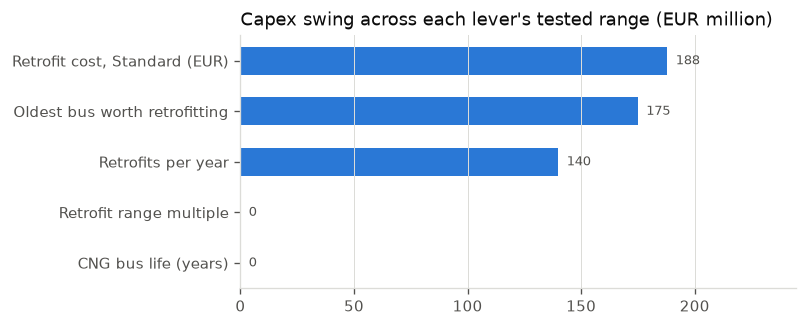


Most decisive lever: Retrofit cost, Standard (EUR) (swings capex by EUR 188 m)


In [13]:
R1 = dict(name="R1 retrofit-led", new_bev_per_year=100, retrofit_per_year=250)

def sweep(label, key, values, transform=lambda v: v):
    rows = []
    for v in values:
        g = simulate({**R1, key: transform(v)})
        rows.append(dict(lever=label, value=v,
                         capex_meur=round(g.capex_meur.sum()),
                         co2_avoided_kt=round(g.co2_avoided_t.sum() / 1000),
                         ze_pct_2035=g.loc[g.year == 2035, "ze_share_pct"].iloc[0],
                         lines_not_feasible=int(g.lines_not_feasible.max()),
                         blocks_over=int(g.blocks_over_range.max())))
    return rows

rows = []
rows += sweep("Retrofit cost, Standard (EUR)", "retro_cost", [150_000, 250_000, 400_000],
              lambda v: {"Standard": v, "Articulated": int(round(v * 1.28))})
rows += sweep("Retrofit range multiple", "retro_range_mult", [0.55, 0.70, 0.85])
rows += sweep("CNG bus life (years)", "bus_life", [12, 14, 16])
rows += sweep("Retrofits per year", "retrofit_per_year", [150, 250, 350])
rows += sweep("Oldest bus worth retrofitting", "retro_max_age", [8, 10, 12])
sens = pd.DataFrame(rows)
display(sens)

tor = (sens.groupby("lever").agg(lo=("capex_meur", "min"), hi=("capex_meur", "max"))
       .assign(swing=lambda d: d.hi - d.lo).sort_values("swing"))
fig, ax = plt.subplots(figsize=(6.8, 2.8))
ax.barh(tor.index, tor.swing, color=C[0], height=0.55)
for y, v in enumerate(tor.swing):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(5, 0), textcoords="offset points",
                fontsize=8, color=INK2, va="center")
ax.set_title("Capex swing across each lever's tested range (EUR million)", color=INK, loc="left")
ax.grid(axis="y", visible=False); ax.set_xlim(0, tor.swing.max() * 1.3)
fig.tight_layout(); plt.show()
print(f"\nMost decisive lever: {tor.index[-1]} (swings capex by EUR {tor.swing.iloc[-1]:,.0f} m)")

## 7 · Assumptions register and open questions

In [14]:
display(pd.DataFrame(ASSUMPTIONS)[["variable", "value", "label", "evidence"]])

print("Placeholders that change the conclusion -- research needed before quoting any number:")
for v in ["Retrofit cost per bus (EUR)",
          "Retrofit range as a share of a new BEV's",
          "CNG bus service life (years)",
          "Oldest CNG bus worth retrofitting (age at conversion, years)",
          "Spain grid CO2 intensity in 2035 (gCO2/kWh)"]:
    print(f"  - {v}")

print("\nNot modelled here:")
for t in ["Opex: electricity against CNG price per km. Decides the business case and is not in P",
          "Residual or stranded value of scrapping a young CNG bus",
          "Per-depot charging power: needs section 5 (allocation) and section 6 (connection MW)",
          "Deadheading km from depot to terminal: needs section 5",
          "Grid connection lead times, which may bind harder than money",
          "Whether CNG-to-electric repowering is a product EMT can actually buy"]:
    print(f"  - {t}")

s = pd.DataFrame(CHECKS)
display(s)
print(f"\n{(s.result == 'PASS').sum()} PASS / {(s.result == 'FAIL').sum()} FAIL")

written = [f for f in ("File_1.csv", "File_2.csv", "File_3.csv", "File_4.csv")
           if os.path.exists(os.path.join(OUT, f))]
print(f"\nDeliverable CSVs in outputs/ (this notebook writes none): {written or 'none present'}")

,variable,value,label,evidence
0,CO2 factor CNG,2.7175,V,MITECO emission factors (inventory annex VII)
1,CO2 factor electricity Spain 2025,108.4,V,Red Electrica 2025 generation emissions
2,Retrofit cost per bus (EUR),"{'Standard': 250000, 'Articulated': 320000}",A,"PLACEHOLDER, not sourced: set at about 40% of ..."
3,Retrofit range as a share of a new BEV's,0.7,A,PLACEHOLDER: a repowered bus carries a smaller...
4,Retrofit energy use as a share of a new BEV's,1.05,A,PLACEHOLDER: a converted bus is heavier and le...
5,Oldest CNG bus worth retrofitting (age at conv...,10,A,PLACEHOLDER: beyond this the body and chassis ...
6,Months a bus is out of service per retrofit,3,A,"PLACEHOLDER: conversion, type approval and com..."
7,CNG bus service life (years),14,A,PLACEHOLDER: typical European urban bus life. ...
8,Charging infrastructure per bus (EUR),40000,A,"PLACEHOLDER: depot charger, civils and a share..."
9,Spain grid CO2 intensity in 2035 (gCO2/kWh),40.0,A,PLACEHOLDER: interpolated linearly from the 20...


Placeholders that change the conclusion -- research needed before quoting any number:
  - Retrofit cost per bus (EUR)
  - Retrofit range as a share of a new BEV's
  - CNG bus service life (years)
  - Oldest CNG bus worth retrofitting (age at conversion, years)
  - Spain grid CO2 intensity in 2035 (gCO2/kWh)

Not modelled here:
  - Opex: electricity against CNG price per km. Decides the business case and is not in P
  - Residual or stranded value of scrapping a young CNG bus
  - Per-depot charging power: needs section 5 (allocation) and section 6 (connection MW)
  - Deadheading km from depot to terminal: needs section 5
  - Grid connection lead times, which may bind harder than money
  - Whether CNG-to-electric repowering is a product EMT can actually buy


,check,result,detail
0,Brief parameters loaded from notebook 01 secti...,PASS,11 parameters
1,Fleet identity at 31 Dec 2025,PASS,
2,Every line has a positive peak_buses and daily_km,PASS,
3,Spare buses over peak demand is positive,PASS,216 buses
4,Every CNG bus has a size and an age,PASS,
5,Fleet identity holds in every scenario-year,PASS,
6,Fleet total stays at the 2025 size,PASS,[np.int64(2210)]
7,ze_share_pct matches the fleet mix,PASS,
8,CNG count never increases,PASS,
9,Retrofits never exceed the CNG fleet that exis...,PASS,



12 PASS / 0 FAIL

Deliverable CSVs in outputs/ (this notebook writes none): none present
